<a href="https://colab.research.google.com/github/van1403/TECHNOLOGY/blob/main/Technology_Solutions_Servicio_Tecnico.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🛠️ TECHNOLOGY SOLUTIONS – Registro de Servicio Técnico

Sistema para registrar, consultar y administrar los servicios técnicos de **Technology Solutions**, hecho en Python con **SQLite** e **ipywidgets** dentro de Google Colab.

**Modelo de datos (relaciones 1 a muchos):**
`empleado` → `tecnico` → `cliente` → `servicio`

**Cómo usarlo:** ejecuta las celdas en orden, de arriba hacia abajo (▶ o `Ctrl + Enter`).

## 1. Configuración inicial
Si pones `USAR_DRIVE = True`, la base de datos se guarda en tu Google Drive y **no se pierde** al cerrar Colab. Con `False` se guarda en `/content`, que se borra cuando la sesión termina.

In [1]:
import os
import sqlite3
from datetime import date

import pandas as pd
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display, clear_output

USAR_DRIVE = False  # Cambia a True para guardar los datos en Google Drive

if USAR_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    CARPETA = '/content/drive/MyDrive/TECHNOLOGY-SOLUTIONS'
else:
    CARPETA = '/content/TECHNOLOGY-SOLUTIONS'

os.makedirs(CARPETA, exist_ok=True)
DB_PATH = os.path.join(CARPETA, 'technology_solutions.db')

def conectar():
    con = sqlite3.connect(DB_PATH)
    con.execute('PRAGMA foreign_keys = ON')
    return con

print('📁 Base de datos:', DB_PATH)

📁 Base de datos: /content/TECHNOLOGY-SOLUTIONS/technology_solutions.db


## 2. Creación de tablas
Mismo modelo entidad-relación: `empleado`, `tecnico`, `cliente` y `servicio`. A `servicio` se le agregan tipo, equipo, descripción y estado.

In [2]:
SQL_TABLAS = """
CREATE TABLE IF NOT EXISTS empleado (
    id_empleado INTEGER PRIMARY KEY AUTOINCREMENT,
    nombre      TEXT NOT NULL,
    cargo       TEXT NOT NULL
);

CREATE TABLE IF NOT EXISTS tecnico (
    id_tecnico   INTEGER PRIMARY KEY AUTOINCREMENT,
    id_empleado  INTEGER NOT NULL UNIQUE,
    especialidad TEXT,
    FOREIGN KEY (id_empleado) REFERENCES empleado(id_empleado)
);

CREATE TABLE IF NOT EXISTS cliente (
    id_cliente INTEGER PRIMARY KEY AUTOINCREMENT,
    id_tecnico INTEGER,
    nombre     TEXT NOT NULL,
    dni        TEXT NOT NULL UNIQUE,
    celular    TEXT,
    FOREIGN KEY (id_tecnico) REFERENCES tecnico(id_tecnico)
);

CREATE TABLE IF NOT EXISTS servicio (
    id_servicio    INTEGER PRIMARY KEY AUTOINCREMENT,
    id_cliente     INTEGER NOT NULL,
    tipo_servicio  TEXT NOT NULL,
    equipo         TEXT,
    descripcion    TEXT,
    monto          REAL NOT NULL CHECK (monto >= 0),
    fecha_servicio TEXT NOT NULL,
    estado         TEXT NOT NULL DEFAULT 'Pendiente',
    FOREIGN KEY (id_cliente) REFERENCES cliente(id_cliente) ON DELETE CASCADE
);
"""

with conectar() as con:
    con.executescript(SQL_TABLAS)

print('✅ Tablas creadas: empleado, tecnico, cliente, servicio')

✅ Tablas creadas: empleado, tecnico, cliente, servicio


## 3. Datos iniciales (empleados y técnicos)
Solo se insertan la primera vez. Puedes cambiar los nombres por los reales.

In [3]:
with conectar() as con:
    if con.execute('SELECT COUNT(*) FROM empleado').fetchone()[0] == 0:
        con.executemany('INSERT INTO empleado (nombre, cargo) VALUES (?, ?)', [
            ('Carlos Ramírez', 'Técnico'),
            ('María Torres', 'Técnico'),
            ('Luis Paredes', 'Técnico'),
            ('Ana Quispe', 'Recepcionista'),
        ])
        con.executemany('INSERT INTO tecnico (id_empleado, especialidad) VALUES (?, ?)', [
            (1, 'Computadoras y laptops'),
            (2, 'Redes e internet'),
            (3, 'Impresoras y periféricos'),
        ])
        print('✅ Empleados y técnicos de ejemplo registrados')
    else:
        print('ℹ️ Ya existen empleados registrados')

with conectar() as con:
    display(pd.read_sql_query('''
        SELECT t.id_tecnico, e.nombre, e.cargo, t.especialidad
        FROM tecnico t JOIN empleado e ON e.id_empleado = t.id_empleado
    ''', con))

✅ Empleados y técnicos de ejemplo registrados


,id_tecnico,nombre,cargo,especialidad
0,1,Carlos Ramírez,Técnico,Computadoras y laptops
1,2,María Torres,Técnico,Redes e internet
2,3,Luis Paredes,Técnico,Impresoras y periféricos


## 4. Funciones del sistema (CRUD)
Lógica del negocio: registrar, listar, actualizar estado y eliminar servicios, con validaciones.

In [4]:
TIPOS_SERVICIO = ['Mantenimiento preventivo', 'Reparación', 'Formateo e instalación de software',
                  'Instalación de redes', 'Recuperación de datos', 'Otro']
ESTADOS = ['Pendiente', 'En proceso', 'Terminado', 'Entregado']


def tecnicos_opciones():
    with conectar() as con:
        filas = con.execute('''
            SELECT t.id_tecnico, e.nombre, t.especialidad
            FROM tecnico t JOIN empleado e ON e.id_empleado = t.id_empleado
            ORDER BY e.nombre
        ''').fetchall()
    return [(f'{nombre} – {esp}', id_tec) for id_tec, nombre, esp in filas]


def validar(nombre, dni, celular, monto):
    if not nombre.strip():
        raise ValueError('El nombre del cliente es obligatorio.')
    if not (dni.isdigit() and len(dni) == 8):
        raise ValueError('El DNI debe tener exactamente 8 dígitos.')
    if celular and not (celular.isdigit() and len(celular) == 9):
        raise ValueError('El celular debe tener 9 dígitos.')
    if monto is None or monto <= 0:
        raise ValueError('El monto debe ser mayor a 0.')


def registrar_servicio(nombre, dni, celular, id_tecnico, tipo, equipo, descripcion, monto, fecha):
    """Registra el cliente (o lo actualiza si el DNI ya existe) y crea el servicio."""
    validar(nombre, dni, celular, monto)
    with conectar() as con:
        fila = con.execute('SELECT id_cliente FROM cliente WHERE dni = ?', (dni,)).fetchone()
        if fila:
            id_cliente = fila[0]
            con.execute('UPDATE cliente SET nombre = ?, celular = ?, id_tecnico = ? WHERE id_cliente = ?',
                        (nombre.strip(), celular, id_tecnico, id_cliente))
        else:
            cur = con.execute('INSERT INTO cliente (id_tecnico, nombre, dni, celular) VALUES (?, ?, ?, ?)',
                              (id_tecnico, nombre.strip(), dni, celular))
            id_cliente = cur.lastrowid
        cur = con.execute('''
            INSERT INTO servicio (id_cliente, tipo_servicio, equipo, descripcion, monto, fecha_servicio, estado)
            VALUES (?, ?, ?, ?, ?, ?, 'Pendiente')
        ''', (id_cliente, tipo, equipo, descripcion, round(monto, 2), fecha))
        return cur.lastrowid


def listar_servicios(dni=None, estado=None):
    q = '''
        SELECT s.id_servicio    AS "N°",
               s.fecha_servicio AS "Fecha",
               c.nombre         AS "Cliente",
               c.dni            AS "DNI",
               c.celular        AS "Celular",
               e.nombre         AS "Técnico",
               s.tipo_servicio  AS "Servicio",
               s.equipo         AS "Equipo",
               s.descripcion    AS "Descripción",
               s.monto          AS "Monto (S/)",
               s.estado         AS "Estado"
        FROM servicio s
        JOIN cliente c       ON c.id_cliente  = s.id_cliente
        LEFT JOIN tecnico t  ON t.id_tecnico  = c.id_tecnico
        LEFT JOIN empleado e ON e.id_empleado = t.id_empleado
        WHERE 1 = 1
    '''
    params = []
    if dni:
        q += ' AND c.dni = ?'
        params.append(dni)
    if estado and estado != 'Todos':
        q += ' AND s.estado = ?'
        params.append(estado)
    q += ' ORDER BY s.id_servicio DESC'
    with conectar() as con:
        return pd.read_sql_query(q, con, params=params)


def actualizar_estado(id_servicio, estado):
    with conectar() as con:
        return con.execute('UPDATE servicio SET estado = ? WHERE id_servicio = ?',
                           (estado, id_servicio)).rowcount


def eliminar_servicio(id_servicio):
    with conectar() as con:
        return con.execute('DELETE FROM servicio WHERE id_servicio = ?', (id_servicio,)).rowcount


print('✅ Funciones cargadas')

✅ Funciones cargadas


## 5. 📝 Formulario: registrar servicio técnico
Si el DNI ya existe, se reutiliza el mismo cliente y se le agrega un nuevo servicio.

In [5]:
estilo = {'description_width': '130px'}
ancho = widgets.Layout(width='480px')

w_nombre = widgets.Text(description='Cliente:', placeholder='Nombre completo', style=estilo, layout=ancho)
w_dni    = widgets.Text(description='DNI:', placeholder='8 dígitos', style=estilo, layout=ancho)
w_cel    = widgets.Text(description='Celular:', placeholder='9 dígitos (opcional)', style=estilo, layout=ancho)
w_tec    = widgets.Dropdown(description='Técnico:', options=tecnicos_opciones(), style=estilo, layout=ancho)
w_tipo   = widgets.Dropdown(description='Tipo de servicio:', options=TIPOS_SERVICIO, style=estilo, layout=ancho)
w_equipo = widgets.Text(description='Equipo:', placeholder='Ej. Laptop HP 15', style=estilo, layout=ancho)
w_desc   = widgets.Textarea(description='Descripción:', placeholder='Falla reportada o trabajo a realizar',
                            style=estilo, layout=widgets.Layout(width='480px', height='80px'))
w_monto  = widgets.BoundedFloatText(description='Monto (S/):', min=0, max=100000, step=0.5, value=0,
                                    style=estilo, layout=ancho)
w_fecha  = widgets.DatePicker(description='Fecha:', value=date.today(), style=estilo)
btn_registrar = widgets.Button(description='Registrar servicio', button_style='success', icon='save')
salida_registro = widgets.Output()

def al_registrar(_):
    with salida_registro:
        clear_output()
        try:
            fecha = (w_fecha.value or date.today()).isoformat()
            nro = registrar_servicio(w_nombre.value, w_dni.value.strip(), w_cel.value.strip(), w_tec.value,
                                     w_tipo.value, w_equipo.value.strip(), w_desc.value.strip(),
                                     w_monto.value, fecha)
            print(f'✅ Servicio N° {nro} registrado correctamente.')
            for w in (w_nombre, w_dni, w_cel, w_equipo, w_desc):
                w.value = ''
            w_monto.value = 0
        except Exception as e:
            print('❌ Error:', e)

btn_registrar.on_click(al_registrar)

display(widgets.VBox([
    widgets.HTML('<h3>Registro de servicio técnico – Technology Solutions</h3>'),
    w_nombre, w_dni, w_cel, w_tec, w_tipo, w_equipo, w_desc, w_monto, w_fecha,
    btn_registrar, salida_registro,
]))

## 6. 🔎 Consultar servicios
Deja el DNI vacío para ver todos.

In [6]:
f_dni = widgets.Text(description='DNI:', placeholder='Vacío = todos')
f_estado = widgets.Dropdown(description='Estado:', options=['Todos'] + ESTADOS)
btn_buscar = widgets.Button(description='Buscar', button_style='info', icon='search')
salida_consulta = widgets.Output()

def al_buscar(_):
    with salida_consulta:
        clear_output()
        df = listar_servicios(f_dni.value.strip() or None, f_estado.value)
        if df.empty:
            print('No se encontraron servicios.')
        else:
            display(df)

btn_buscar.on_click(al_buscar)
display(widgets.HBox([f_dni, f_estado, btn_buscar]), salida_consulta)
al_buscar(None)

Output()

## 7. ✏️ Actualizar estado o eliminar un servicio
Usa el **N°** del servicio que aparece en la consulta.

In [7]:
u_id = widgets.IntText(description='N° servicio:')
u_estado = widgets.Dropdown(description='Nuevo estado:', options=ESTADOS)
btn_actualizar = widgets.Button(description='Actualizar estado', button_style='warning', icon='edit')
btn_eliminar = widgets.Button(description='Eliminar servicio', button_style='danger', icon='trash')
salida_admin = widgets.Output()

def al_actualizar(_):
    with salida_admin:
        clear_output()
        if actualizar_estado(u_id.value, u_estado.value):
            print(f'✅ Servicio N° {u_id.value} ahora está "{u_estado.value}".')
        else:
            print('❌ No existe un servicio con ese número.')

def al_eliminar(_):
    with salida_admin:
        clear_output()
        if eliminar_servicio(u_id.value):
            print(f'🗑️ Servicio N° {u_id.value} eliminado.')
        else:
            print('❌ No existe un servicio con ese número.')

btn_actualizar.on_click(al_actualizar)
btn_eliminar.on_click(al_eliminar)
display(widgets.VBox([u_id, u_estado, widgets.HBox([btn_actualizar, btn_eliminar]), salida_admin]))

## 8. 📊 Reporte de servicios

Total de servicios: 1
Ingresos totales: S/ 80.00
Servicios pendientes: 1


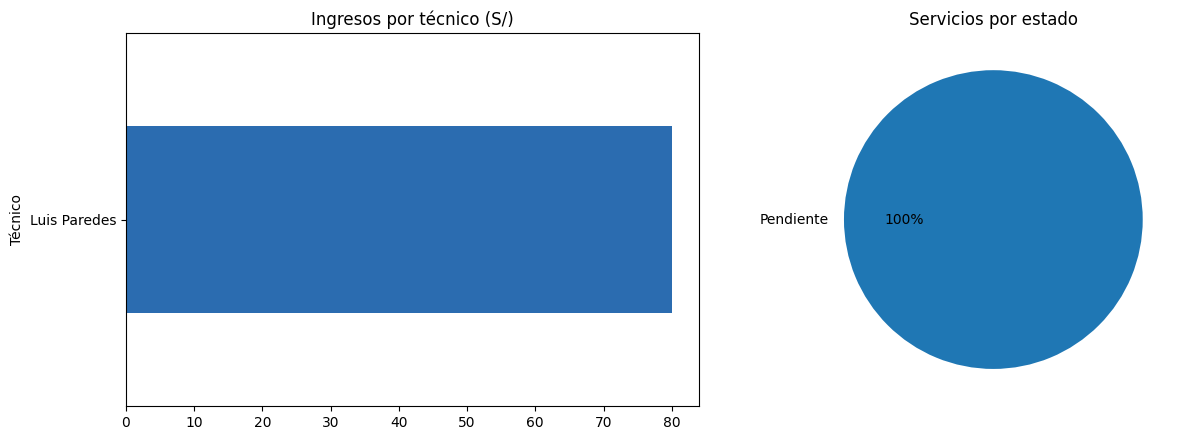

,Cantidad,Ingresos
Servicio,,
Formateo e instalación de software,1,80.0


In [8]:
df = listar_servicios()

if df.empty:
    print('Aún no hay servicios registrados.')
else:
    print(f'Total de servicios: {len(df)}')
    print(f'Ingresos totales: S/ {df["Monto (S/)"].sum():,.2f}')
    print(f'Servicios pendientes: {(df["Estado"] == "Pendiente").sum()}')

    fig, ejes = plt.subplots(1, 2, figsize=(13, 4.5))
    df.groupby('Técnico')['Monto (S/)'].sum().sort_values().plot(
        kind='barh', ax=ejes[0], color='#2b6cb0', title='Ingresos por técnico (S/)')
    df['Estado'].value_counts().plot(
        kind='pie', ax=ejes[1], autopct='%1.0f%%', title='Servicios por estado')
    ejes[1].set_ylabel('')
    plt.tight_layout()
    plt.show()

    display(df.groupby('Servicio').agg(Cantidad=('N°', 'count'), Ingresos=('Monto (S/)', 'sum')))

## 9. 📥 Exportar a Excel

In [9]:
from google.colab import files

ruta_excel = os.path.join(CARPETA, 'servicios_technology_solutions.xlsx')
listar_servicios().to_excel(ruta_excel, index=False)
files.download(ruta_excel)
print('✅ Excel generado:', ruta_excel)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

✅ Excel generado: /content/TECHNOLOGY-SOLUTIONS/servicios_technology_solutions.xlsx


## 10. 💾 Guardar el notebook en GitHub
Sin escribir tokens en el código:
1. Menú **Archivo → Guardar una copia en GitHub**.
2. Autoriza tu cuenta y elige el repositorio `van1403/TECHNOLOGY-SOLUTIONS`.
3. Escribe un mensaje de commit (ej. *"Registro de servicio técnico en Colab"*) y confirma.